# Task 3 – Object Recognition: Viola–Jones (Haar) vs YOLO (Unit 5)

**Inputs:** my two photographs and frames from my self-recorded video (a puppy in a garden)

**What this notebook does**
1. Applies pretrained **Haar cascade** classifiers (Viola–Jones) to detect faces, eyes and full bodies
2. Applies a pretrained **YOLOv8n** model to detect objects
3. Displays bounding boxes, class labels and confidence scores
4. Compares the two detectors
5. Identifies cases where a detector **misses** an object or makes an **incorrect** detection

Outputs are saved to `outputs/task3/`.

## 0. Setup

In [1]:
import os
import time
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from ultralytics import YOLO

%matplotlib inline
plt.rcParams["figure.dpi"] = 100
OUT = "outputs/task3"
os.makedirs(OUT, exist_ok=True)


def show(images, titles, cols=3, size=4.0, suptitle=None, save_as=None):
    rows = (len(images) + cols - 1) // cols
    h, w = images[0].shape[:2]
    fig, axes = plt.subplots(rows, cols, figsize=(cols * size, rows * (size * h / w + 0.45) + 0.5))
    axes = np.array(axes).ravel()
    for ax in axes:
        ax.axis("off")
    for ax, im, t in zip(axes, images, titles):
        ax.imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB))
        ax.set_title(t, fontsize=10)
    if suptitle:
        fig.suptitle(suptitle, fontsize=13)
    fig.tight_layout()
    if save_as:
        fig.savefig(f"{OUT}/{save_as}", dpi=110)
    plt.show()


def load(path, width=750):
    im = cv2.imread(path)
    return cv2.resize(im, (width, int(im.shape[0] * width / im.shape[1])), interpolation=cv2.INTER_AREA)


def put_label(img, text, x, y, col):
    (tw, th), _ = cv2.getTextSize(text, cv2.FONT_HERSHEY_SIMPLEX, 0.55, 1)
    y = max(y, th + 6)
    cv2.rectangle(img, (x, y - th - 6), (x + tw + 4, y), col, -1)
    cv2.putText(img, text, (x + 2, y - 4), cv2.FONT_HERSHEY_SIMPLEX, 0.55, (0, 0, 0), 1, cv2.LINE_AA)

## 1. Viola–Jones detector (Haar cascades)
The Viola–Jones method (2001):
- **Haar-like features:** simple rectangle patterns (light/dark) measured very quickly with an *integral image*.
- **AdaBoost** selects the most useful features out of many thousands.
- A **cascade** of stages rejects non-face windows early, so only promising windows reach the later stages. This makes it fast on a CPU.
- It slides a window over the image at many scales (`scaleFactor`). `minNeighbors` sets how many overlapping detections are needed to accept one.

It gives **only a box, no class probability or confidence score**, and each cascade detects only the single object type it was trained on.

The cascade XML files are in `models/`. Newer OpenCV versions no longer bundle them inside `cv2.data`.

In [2]:
def load_cascade(fname):
    for folder in ["models", getattr(getattr(cv2, "data", None), "haarcascades", "")]:
        c = cv2.CascadeClassifier(os.path.join(folder, fname))
        if not c.empty():
            return c
    raise FileNotFoundError(fname)


cascades = {
    "face": load_cascade("haarcascade_frontalface_default.xml"),
    "eye": load_cascade("haarcascade_eye.xml"),
    "fullbody": load_cascade("haarcascade_fullbody.xml"),
    "cat face": load_cascade("haarcascade_frontalcatface_extended.xml"),  # OpenCV has no dog cascade
}
params = {
    "face": dict(scaleFactor=1.1, minNeighbors=5, minSize=(30, 30)),
    "eye": dict(scaleFactor=1.1, minNeighbors=8, minSize=(12, 12)),
    "fullbody": dict(scaleFactor=1.05, minNeighbors=3, minSize=(60, 120)),
    "cat face": dict(scaleFactor=1.1, minNeighbors=5, minSize=(30, 30)),
}
colours = {"face": (0, 255, 0), "eye": (255, 200, 0), "fullbody": (255, 0, 255), "cat face": (0, 165, 255)}


def run_haar(img, which):
    gray = cv2.equalizeHist(cv2.cvtColor(img, cv2.COLOR_BGR2GRAY))
    vis, counts = img.copy(), {}
    t = time.perf_counter()
    for name in which:
        boxes = cascades[name].detectMultiScale(gray, **params[name])
        counts[name] = len(boxes)
        for (x, y, w, h) in boxes:
            cv2.rectangle(vis, (x, y), (x + w, y + h), colours[name], 2)
            put_label(vis, name, x, y, colours[name])
    return vis, counts, (time.perf_counter() - t) * 1000

## 2. YOLO (You Only Look Once)
YOLOv8n ("nano") is a convolutional neural network trained on the **COCO dataset (80 classes)**, including person, dog, cat, car and potted plant.
- It processes the **whole image in one forward pass** and predicts boxes, class labels and a **confidence score** for each.
- Non-maximum suppression removes duplicate boxes.
- I use a confidence threshold of 0.25.

The weights (`yolov8n.pt`, 6 MB) download automatically the first time.

In [3]:
yolo = YOLO("yolov8n.pt")
CONF = 0.25
print("YOLO can detect", len(yolo.names), "classes, e.g.:", list(yolo.names.values())[:12], "...")


def run_yolo(img):
    t = time.perf_counter()
    r = yolo(img, conf=CONF, verbose=False)[0]
    ms = (time.perf_counter() - t) * 1000
    vis, dets = img.copy(), []
    for b in r.boxes:
        x1, y1, x2, y2 = map(int, b.xyxy[0])
        name, conf = yolo.names[int(b.cls)], float(b.conf)
        dets.append((name, conf))
        col = (0, 255, 0) if name == "person" else (255, 120, 0) if name == "dog" else (0, 200, 255)
        cv2.rectangle(vis, (x1, y1), (x2, y2), col, 2)
        put_label(vis, f"{name} {conf:.2f}", x1, y1, col)
    return vis, dets, ms


def describe(dets):
    out = {}
    for n, c in dets:
        out.setdefault(n, []).append(c)
    return "; ".join(f"{n} ×{len(c)} ({', '.join(f'{v:.2f}' for v in c)})" for n, c in out.items()) or "none"


_ = run_yolo(load("data/photo1.jpg"))   # warm-up run so the timings below are fair

YOLO can detect 80 classes, e.g.: ['person', 'bicycle', 'car', 'motorcycle', 'airplane', 'bus', 'train', 'truck', 'boat', 'traffic light', 'fire hydrant', 'stop sign'] ...


## 3. Detection on the photographs

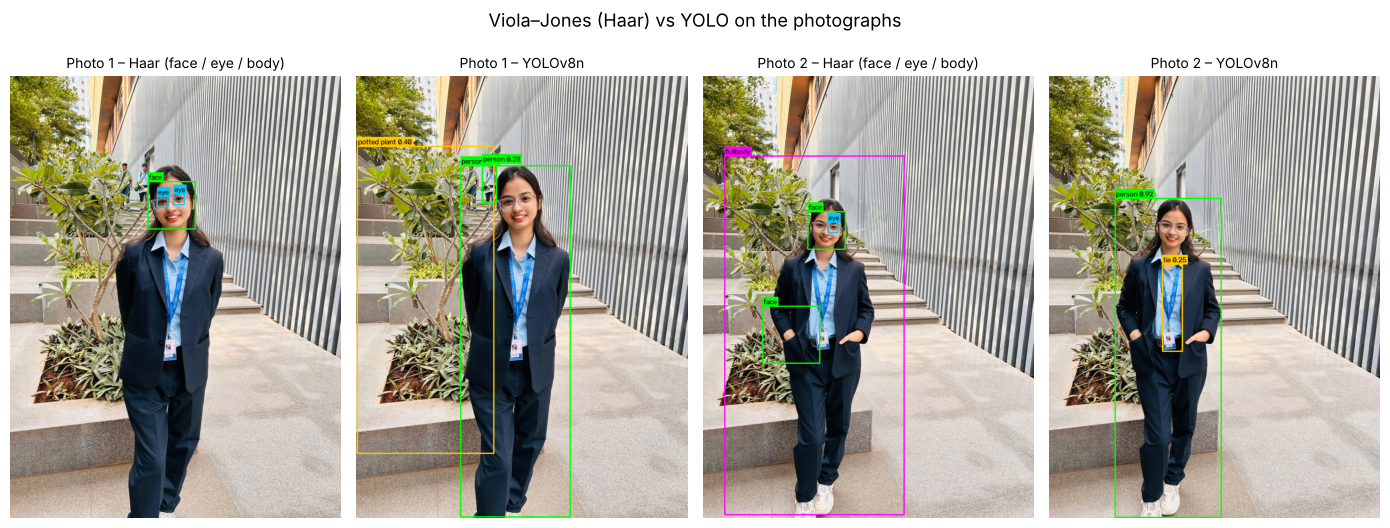

In [4]:
rows, figs, titles = [], [], []
for name, path in [("Photo 1", "data/photo1.jpg"), ("Photo 2", "data/photo2.jpg")]:
    img = load(path)
    hv, counts, hms = run_haar(img, ["face", "eye", "fullbody"])
    yv, dets, yms = run_yolo(img)
    tag = name.replace(" ", "").lower()
    cv2.imwrite(f"{OUT}/haar_{tag}.jpg", hv)
    cv2.imwrite(f"{OUT}/yolo_{tag}.jpg", yv)
    figs += [hv, yv]
    titles += [f"{name} – Haar (face / eye / body)", f"{name} – YOLOv8n"]
    rows.append([name, "Haar cascades", ", ".join(f"{k}: {v}" for k, v in counts.items()), "No", round(hms)])
    rows.append([name, "YOLOv8n", describe(dets), "Yes", round(yms)])

show(figs, titles, cols=4, size=3.5, suptitle="Viola–Jones (Haar) vs YOLO on the photographs",
     save_as="fig1_photos_haar_vs_yolo.png")

## 4. Detection on video frames
The video shows a puppy. There is no Haar cascade for dogs, so I try the **cat-face** cascade (the closest animal model OpenCV provides) together with the human face cascade. This shows what happens when a detector is used outside what it was trained on.

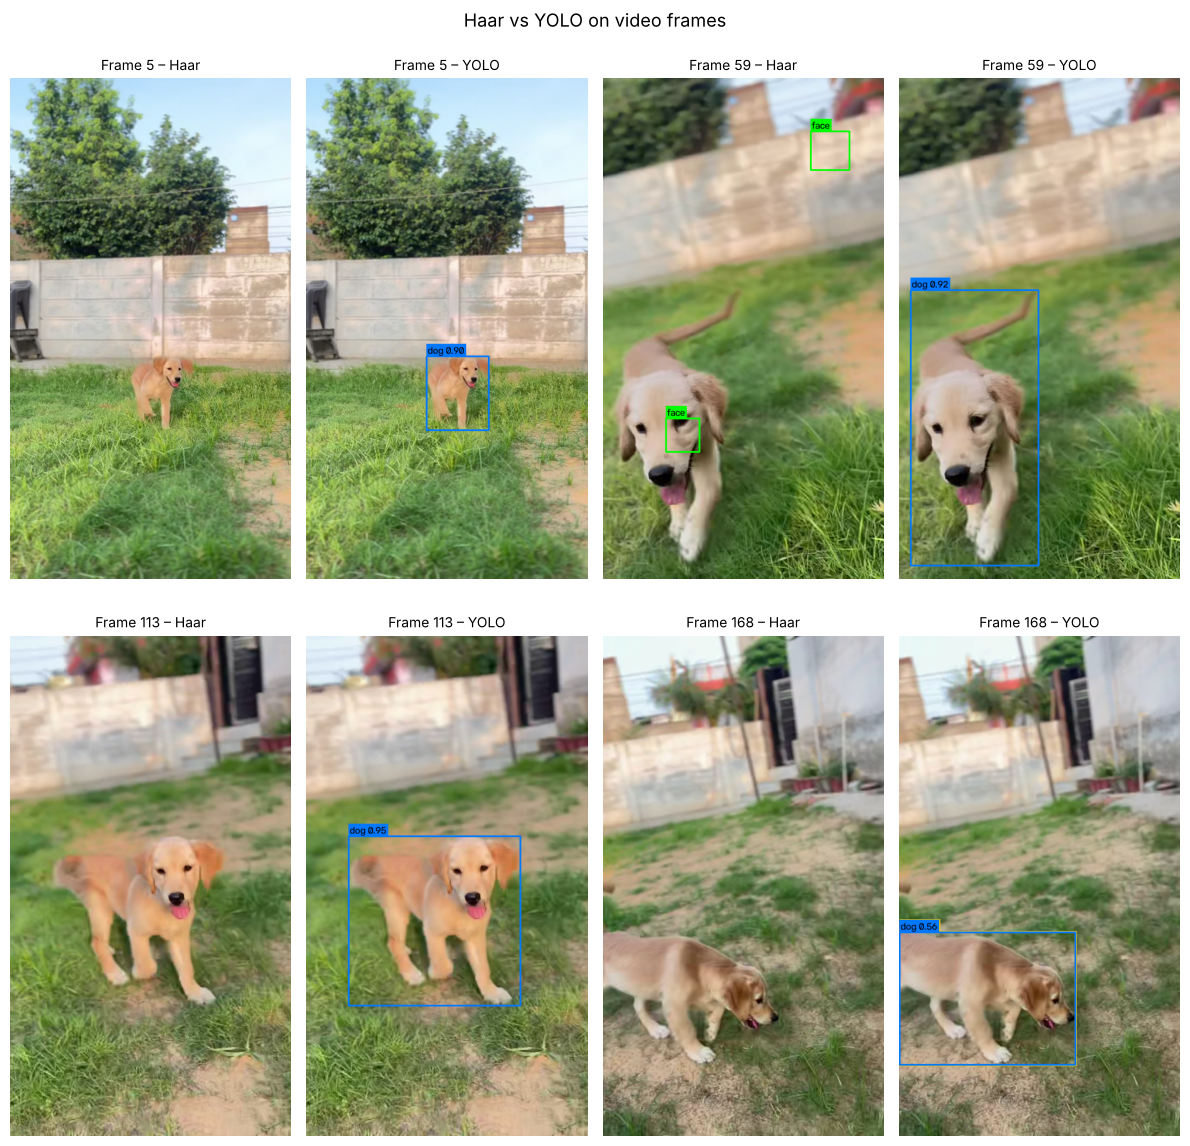

In [5]:
cap = cv2.VideoCapture("data/video.mp4")
total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
frame_ids = np.linspace(5, total - 5, 4).astype(int)
figs, titles = [], []
for i in frame_ids:
    cap.set(cv2.CAP_PROP_POS_FRAMES, int(i))
    ok, frame = cap.read()
    hv, counts, hms = run_haar(frame, ["face", "cat face"])
    yv, dets, yms = run_yolo(frame)
    cv2.imwrite(f"{OUT}/frame{i:03d}_haar.jpg", hv)
    cv2.imwrite(f"{OUT}/frame{i:03d}_yolo.jpg", yv)
    figs += [hv, yv]
    titles += [f"Frame {i} – Haar", f"Frame {i} – YOLO"]
    rows.append([f"Video frame {i}", "Haar cascades", ", ".join(f"{k}: {v}" for k, v in counts.items()), "No", round(hms)])
    rows.append([f"Video frame {i}", "YOLOv8n", describe(dets), "Yes", round(yms)])
cap.release()
show(figs, titles, cols=4, size=3.0, suptitle="Haar vs YOLO on video frames", save_as="fig2_video_haar_vs_yolo.png")

## 5. Detection results table

In [6]:
table_det = pd.DataFrame(rows, columns=["Input", "Detector", "Detections (confidence)", "Gives confidence?", "Time (ms)"])
table_det.to_csv(f"{OUT}/table_detections.csv", index=False)
pd.set_option("display.max_colwidth", 80)
table_det

,Input,Detector,Detections (confidence),Gives confidence?,Time (ms)
0,Photo 1,Haar cascades,"face: 1, eye: 2, fullbody: 0",No,1104
1,Photo 1,YOLOv8n,"person ×2 (0.89, 0.28); potted plant ×1 (0.40)",Yes,105
2,Photo 2,Haar cascades,"face: 2, eye: 1, fullbody: 1",No,1102
3,Photo 2,YOLOv8n,person ×1 (0.92); tie ×1 (0.25),Yes,99
4,Video frame 5,Haar cascades,"face: 0, cat face: 0",No,663
5,Video frame 5,YOLOv8n,dog ×1 (0.90),Yes,100
6,Video frame 59,Haar cascades,"face: 2, cat face: 0",No,607
7,Video frame 59,YOLOv8n,dog ×1 (0.92),Yes,89
8,Video frame 113,Haar cascades,"face: 0, cat face: 0",No,623
9,Video frame 113,YOLOv8n,dog ×1 (0.95),Yes,91


## 6. YOLO on every frame of the video
To measure how consistent YOLO is, I run it on all frames and save an annotated video (`yolo_video_annotated.mp4`).

In [7]:
cap = cv2.VideoCapture("data/video.mp4")
fps = cap.get(cv2.CAP_PROP_FPS) or 30
w, h = int(cap.get(3)), int(cap.get(4))
writer = cv2.VideoWriter(f"{OUT}/yolo_video_annotated.mp4", cv2.VideoWriter_fourcc(*"mp4v"), fps, (w, h))
n, dog_frames, dog_conf, others, times, wrong_examples = 0, 0, [], {}, [], []
while True:
    ok, frame = cap.read()
    if not ok:
        break
    vis, dets, ms = run_yolo(frame)
    writer.write(vis)
    times.append(ms)
    d = [c for name, c in dets if name == "dog"]
    if d:
        dog_frames += 1
        dog_conf.append(max(d))
    for name, c in dets:
        if name != "dog":
            others[name] = others.get(name, 0) + 1
            if name in ("cow", "frisbee") and name not in [w[2] for w in wrong_examples]:
                wrong_examples.append((n, vis, name))
    n += 1
cap.release(); writer.release()

table_video = pd.DataFrame([
    ["Frames processed", n],
    ["Frames with 'dog' detected", f"{dog_frames} ({100 * dog_frames / n:.1f}%)"],
    ["Mean / min dog confidence", f"{np.mean(dog_conf):.2f} / {np.min(dog_conf):.2f}"],
    ["Other (wrong) classes, frames", ", ".join(f"{k}: {v}" for k, v in others.items())],
    ["Mean YOLO time per frame (CPU)", f"{np.mean(times):.0f} ms"],
], columns=["Metric", "Value"])
table_video.to_csv(f"{OUT}/table_video_yolo.csv", index=False)
table_video

,Metric,Value
0,Frames processed,173
1,Frames with 'dog' detected,171 (98.8%)
2,Mean / min dog confidence,0.90 / 0.47
3,"Other (wrong) classes, frames","frisbee: 18, cow: 7, sheep: 1, book: 2, potted plant: 2"
4,Mean YOLO time per frame (CPU),89 ms


### Example of an incorrect YOLO detection
Two kinds of wrong label appear in the video:
- **"cow"**: the whole puppy, seen from the side with its head down, is labelled as a cow (in some frames *instead of* "dog")
- **"frisbee"**: a *part* of the puppy (its curled tail, or its pink tongue) is detected as a separate object

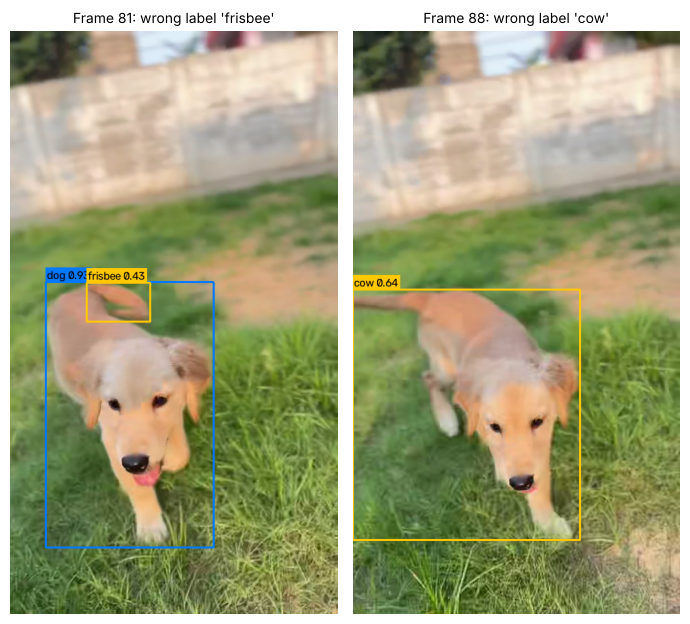

In [8]:
if wrong_examples:
    for i, v, lbl in wrong_examples:
        cv2.imwrite(f"{OUT}/yolo_wrong_{lbl}_frame{i:03d}.jpg", v)
    show([v for _, v, _ in wrong_examples], [f"Frame {i}: wrong label '{lbl}'" for i, _, lbl in wrong_examples],
         cols=len(wrong_examples), size=3.5, save_as="fig3_yolo_errors.png")

## 7. Comparison and error analysis

**Misses and incorrect detections that I found:**

| Case | Detector | What happened | Likely reason |
|---|---|---|---|
| Photo 2 | Haar face | A second "face" on the jacket/plant area (**false positive**) | A light/dark pattern that resembles the Haar face template |
| Video frame 59 | Haar face | "Faces" on the wall and on the puppy's head (**false positive**) | Haar features are simple contrast patterns, so texture can trigger them |
| All video frames | Haar cat-face | The puppy was **never** detected (**miss**) | The model was trained only on frontal cat faces, not dogs |
| Photo 1 | Haar face / full body | Background people on the stairs **missed**; full body also missed on the main person | Faces too small or blurred; arms behind the back change the silhouette |
| Photo 2 | YOLO | ID-card lanyard detected as **"tie"** (0.25) | Long narrow vertical object on a shirt, like a tie in COCO training images |
| Video, 7 frames | YOLO | Puppy also labelled **"cow"** | Side view with head down, motion blur, similar four-legged shape |
| Video, 18 frames | YOLO | Curled tail or pink tongue detected as **"frisbee"** | A small curved, coloured shape out of context, like frisbees in COCO images |
| Photo 1 | YOLO | Background person detected with low confidence (0.28) | Small and partly hidden by the tree |

**Overall comparison:**

| Aspect | Viola–Jones (Haar) | YOLOv8n |
|---|---|---|
| Method | Hand-crafted Haar features + AdaBoost cascade | Deep CNN, single forward pass |
| Classes | One per cascade (face, eye, body…) | 80 COCO classes at once |
| Output | Box only, **no confidence** | Box + class label + **confidence score** |
| Accuracy here | Found frontal faces, but several false positives; cannot detect dogs | Person and dog found reliably (dog in about 99% of frames, mean conf. about 0.9) |
| Robustness | Sensitive to pose, scale, lighting and texture | Handles pose, blur and partial views much better |
| Speed / hardware | Fast, light, no GPU; old-school embedded use | Heavier (needs PyTorch) but still about 0.1 s per frame on a laptop CPU |

**Conclusion:** Haar cascades are lightweight and still fine for frontal faces in controlled images, but they are brittle and limited to one object type. YOLO is clearly more accurate and more general on my real photos and video, and its confidence scores help in filtering. Its remaining errors are mostly confusions between visually similar classes (dog/cow, lanyard/tie).